### Problem 2 : Linear & Logistic Regression - from exact downdates to the first approximation

⏱️ ~30 min · 🧭 Stage 1 (Classical ML), rung 2 · 📄 `resources/papers/01-foundations/2019-guo-certified-data-removal.pdf`

> 🔗 **Building on Problem 1 :** Naive Bayes and k-NN were *independent sums* - each training point contributed its own
> term, so we could subtract it. Two things break that, one after the other :
>
> 1. **Coupled sums** - ridge regression is still built from sums (`XᵀX`, `Xᵀy`), but the answer needs a matrix
>    **inverse**, which mixes every point with every other. → *Part A: we can still forget exactly, with one line of
>    linear algebra.*
> 2. **No formula at all** - logistic regression's weights are defined only as "the point where the gradient is zero".
>    → *Part B: forgetting becomes **approximate** for the first time - and we must start **measuring** how close we got.*

Same lab, same request : **Carol** (40 thick-marker digits) invokes her right to erasure.

**TASK :** Make ridge regression forget Carol exactly, then make logistic regression forget her approximately - and
measure how close "approximately" really is.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, classical, viz
viz.style()

L = lab.make_lab("carol")
acc = lambda m, X, y: float((m.predict(X) == y).mean())
onehot = lambda y: np.eye(10)[y]
print(L)

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540)


----
### Part A : Ridge regression - coupled, but still exactly reversible

> 🟢 **In plain words :** ridge regression finds the straight-line (here: flat-plane) fit that best matches the data.
> The answer comes from a formula that uses two "summary tables" built by adding up every training point. Removing a
> point changes both tables a little - and a classic trick from linear algebra updates the answer **without
> recomputing it from scratch**.

> 🔴 **For practitioners :** `w = (XᵀX + λI)⁻¹ Xᵀy`. Removing `(x, y)` gives `A' = A − xxᵀ` and `b' = b − xy`. The
> Sherman-Morrison identity updates the inverse in O(d²):
> `A'⁻¹ = A⁻¹ + (A⁻¹x xᵀA⁻¹) / (1 − xᵀA⁻¹x)`. Here we fit one-hot targets (a "least-squares classifier").

#### Step 1 : Train

In [2]:
# Step 1: fit ridge on one-hot targets (a least-squares classifier)
ridge = classical.RidgeUnlearner(lam=1.0).fit(L.X_train, onehot(L.y_train))
ridge.predict_cls = lambda X: ridge.predict(X).argmax(1)
print(f"ridge | test {np.mean(ridge.predict_cls(L.X_test) == L.y_test):.1%} | Carol {np.mean(ridge.predict_cls(L.Xf) == L.yf):.1%} "
      f"| unseen thick {np.mean(ridge.predict_cls(L.X_like_forget) == L.y_like_forget):.1%}")

ridge | test 94.6% | Carol 95.0% | unseen thick 67.5%


#### Step 2 : Show the issue: *leverage*, the classical fingerprint of memorisation

Linear models have a beautiful, exact measure of how much a single training point bends the model: its **leverage**
`h = xᵀ(XᵀX + λI)⁻¹x`. A point with high leverage pulls the fit towards itself; it is the classical ancestor of what deep
learning calls *memorisation* (Problem 4).

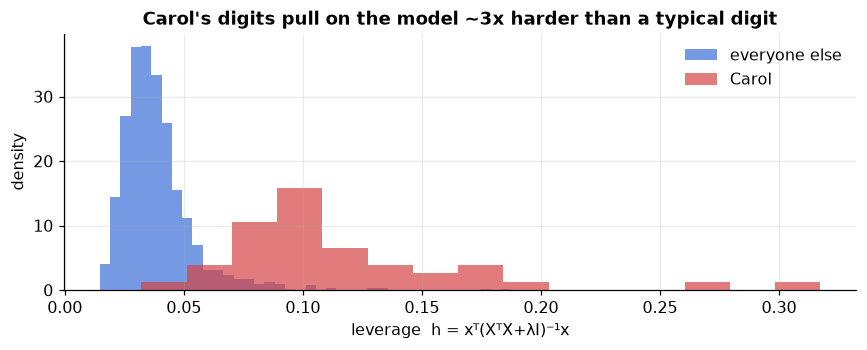

mean leverage: Carol 0.116  vs  others 0.039


In [3]:
# Step 2: leverage of every training point
h = ridge.leverage(L.X_train)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(h[L.retain_idx], bins=40, color=viz.RETAIN, alpha=0.7, density=True, label="everyone else")
ax.hist(h[L.forget_idx], bins=15, color=viz.FORGET, alpha=0.7, density=True, label="Carol")
ax.set_xlabel("leverage  h = xᵀ(XᵀX+λI)⁻¹x"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Carol's digits pull on the model ~3x harder than a typical digit"); plt.tight_layout(); plt.show()
print(f"mean leverage: Carol {h[L.forget_idx].mean():.3f}  vs  others {h[L.retain_idx].mean():.3f}")

**Atypical data has high leverage, and high-leverage data is what a model remembers individually.** That is why Carol
(not a random user) is the hard case throughout this course.

#### Step 3 : Untrain: 40 Sherman-Morrison downdates

In [4]:
# Step 3: unlearn Carol with Sherman-Morrison, and time it against a refit
ridge_before = classical.RidgeUnlearner(lam=1.0).fit(L.X_train, onehot(L.y_train))
t0 = time.perf_counter(); ridge.unlearn(L.Xf, onehot(L.yf)); t_down = time.perf_counter() - t0
t0 = time.perf_counter(); ridge_scratch = classical.RidgeUnlearner(lam=1.0).fit(L.Xr, onehot(L.yr)); t_fit = time.perf_counter() - t0
print(f"downdate 40 points : {t_down*1e3:6.2f} ms    O(|D_f| · d²)  - depends only on what you delete")
print(f"refit from scratch : {t_fit*1e3:6.2f} ms    O(|D_r| · d² + d³)  - depends on EVERYTHING you keep")

downdate 40 points :   0.53 ms    O(|D_f| · d²)  - depends only on what you delete
refit from scratch :   0.18 ms    O(|D_r| · d² + d³)  - depends on EVERYTHING you keep


On 1,217 rows the refit is just as fast - the lab is tiny. The point is how each cost **scales**. Let's grow the
training set (synthetic rows with the same 64 features) and delete the same 40 points each time :

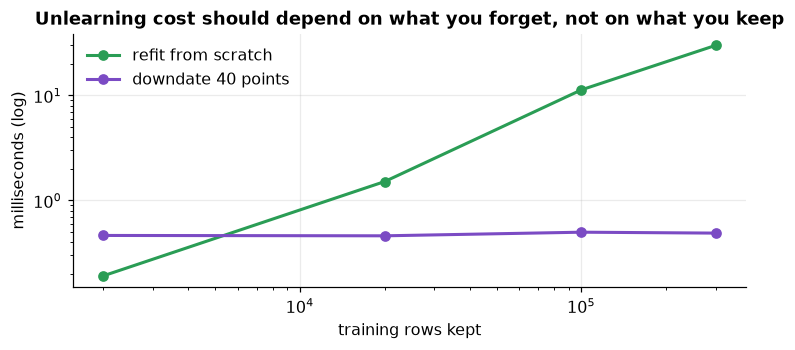

   2,000 rows: refit      0.2 ms | downdate   0.46 ms |    0.4x
  20,000 rows: refit      1.5 ms | downdate   0.46 ms |    3.3x
 100,000 rows: refit     11.3 ms | downdate   0.50 ms |   22.7x
 300,000 rows: refit     30.0 ms | downdate   0.49 ms |   61.6x


In [5]:
rng = np.random.default_rng(0)
sizes, t_refit, t_dd = [2_000, 20_000, 100_000, 300_000], [], []
for n in sizes:
    Xb = rng.random((n, 64)); Yb = onehot(rng.integers(0, 10, n))
    t0 = time.perf_counter(); m = classical.RidgeUnlearner(1.0).fit(Xb, Yb); t_refit.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); m.unlearn(Xb[:40], Yb[:40]); t_dd.append(time.perf_counter() - t0)
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.loglog(sizes, np.array(t_refit) * 1e3, "o-", color=viz.RETRAIN, lw=2, label="refit from scratch")
ax.loglog(sizes, np.array(t_dd) * 1e3, "o-", color=viz.METHOD, lw=2, label="downdate 40 points")
ax.set_xlabel("training rows kept"); ax.set_ylabel("milliseconds (log)"); ax.legend()
ax.set_title("Unlearning cost should depend on what you forget, not on what you keep"); plt.tight_layout(); plt.show()
for n, a, b in zip(sizes, t_refit, t_dd):
    print(f"{n:>8,} rows: refit {a*1e3:8.1f} ms | downdate {b*1e3:6.2f} ms | {a / b:6.1f}x")

#### Step 4 : Show the result, and Step 5 : Prove it

In [6]:
cls = lambda m, X: m.predict(X).argmax(1)
print(f"{'':32s}{'before':>9s}{'after':>9s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:32s}{np.mean(cls(ridge_before, X) == y):9.1%}{np.mean(cls(ridge, X) == y):9.1%}{np.mean(cls(ridge_scratch, X) == y):17.1%}")
print(f"\nmax |w_downdated − w_scratch| = {np.abs(ridge.w - ridge_scratch.w).max():.2e}   (floating-point round-off)")

                                   before    after  never saw Carol
accuracy on Carol (D_f)             95.0%    45.0%            45.0%
accuracy on unseen thick            67.5%    48.8%            48.8%
accuracy on test                    94.6%    93.9%            93.9%

max |w_downdated − w_scratch| = 4.38e-13   (floating-point round-off)


✅ **Exact.** The coupling through the inverse did not stop us - because the model was still a closed-form function of
sums, there was an exact algebraic way to take a point back out.

> 🔴 **For practitioners :** Sherman-Morrison is numerically fragile when `1 − h ≈ 0` (deleting a point the fit depends on
> almost entirely) and errors accumulate over thousands of downdates. Production systems use a Cholesky *downdate* or
> periodic refactorisation. Note also `h < 1` always holds for ridge (λ > 0) - one more reason regularisation helps.

----
### Part B : Logistic regression - no formula, so we *estimate* the removal

> 🟢 **In plain words :** logistic regression has no "summary table" formula. Its weights are found by walking downhill
> on the loss until the slope is flat. If we remove Carol, the bottom of the valley moves a little. We don't know
> exactly where it moved to - but we know the **slope** and the **curvature** of the valley where we are, and from those
> we can *estimate* the new bottom in one jump. That jump is a **Newton step**, and it is the first *approximate*
> unlearning method in this course.

> 🔴 **For practitioners :** at the old optimum `∇L(w) = 0`, so on the retain objective `∇L_r(w) = −Σ_{i∈D_f} ∇ℓᵢ(w)`.
> One Newton step `w_u = w − H_r⁻¹∇L_r(w)` is the **influence-function** estimate of retraining (Koh & Liang 2017) and
> the core of **certified removal** (Guo et al. 2019), which bounds the residual gradient `‖∇L_r(w_u)‖` and adds noise
> at training time to turn it into an (ε, δ) guarantee.

#### Step 1 : Train (multinomial logistic regression, solved to optimality by Newton's method)

In [7]:
# Step 1: multinomial logistic regression, trained to the exact optimum
logreg = classical.SoftmaxNewton(lam=1.0).fit(L.X_train, L.y_train)
print(f"converged in {logreg.n_iter} Newton iterations; ‖∇L(w)‖ on D = {logreg.grad_norm(L.X_train, L.y_train):.1e}  (≈ 0: at the optimum)")

converged in 7 Newton iterations; ‖∇L(w)‖ on D = 5.9e-14  (≈ 0: at the optimum)


#### Step 2 : Show the issue

In [8]:
# Step 2: compare with the gold standard - a model that never saw Carol
logreg_scratch = classical.SoftmaxNewton(lam=1.0).fit(L.Xr, L.yr)
print(f"{'':30s}{'original':>10s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:30s}{acc(logreg, X, y):10.1%}{acc(logreg_scratch, X, y):17.1%}")

                                original  never saw Carol
accuracy on Carol (D_f)            92.5%            62.5%
accuracy on unseen thick           77.5%            57.5%
accuracy on test                   97.2%            97.0%


Logistic regression memorises Carol much more than Naive Bayes did: it is right on **her** digits far more often than on
unseen digits in the same style. That gap is what we must remove.

#### Step 3 : Untrain with one Newton step

In [9]:
# Step 3: one Newton step on the retain-only objective
t0 = time.perf_counter()
logreg_u1 = logreg.unlearn_newton(L.Xr, L.yr, steps=1)
t_newton = time.perf_counter() - t0
print(f"one Newton step: {t_newton*1e3:.1f} ms   vs full refit: {logreg_scratch.fit_seconds*1e3:.1f} ms ({logreg_scratch.n_iter} Newton iterations from zero)")

one Newton step: 6.0 ms   vs full refit: 40.7 ms (7 Newton iterations from zero)


#### Step 4 : Show the result

In [10]:
print(f"{'':30s}{'before':>9s}{'after (1 step)':>16s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:30s}{acc(logreg, X, y):9.1%}{acc(logreg_u1, X, y):16.1%}{acc(logreg_scratch, X, y):17.1%}")

                                 before  after (1 step)  never saw Carol
accuracy on Carol (D_f)           92.5%           60.0%            62.5%
accuracy on unseen thick          77.5%           57.5%            57.5%
accuracy on test                  97.2%           97.0%            97.0%


#### Step 5 : Prove it ... or rather, *measure* it

For the first time there is no "identical" to check. The honest question becomes **how far** the unlearned weights are
from the gold standard, compared with how far the original weights were.

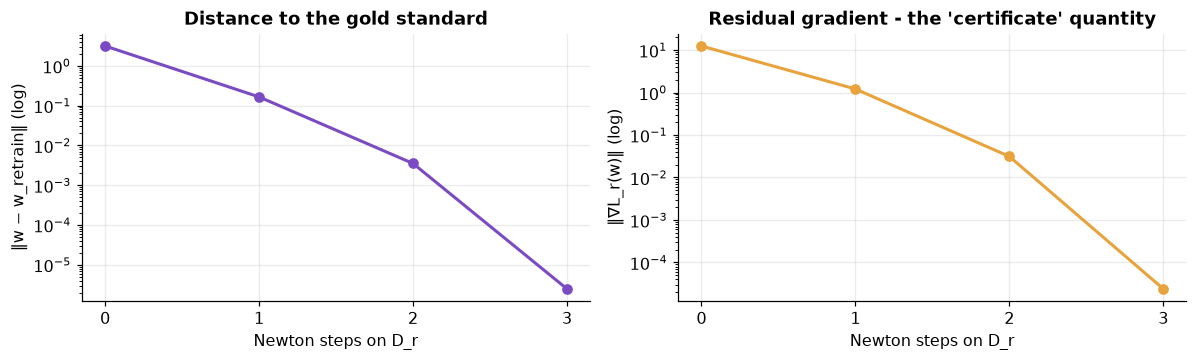

0 step(s): gap to retrain   3.14814  (  0.0% of the gap closed)   residual gradient 1.25e+01
1 step(s): gap to retrain   0.16506  ( 94.8% of the gap closed)   residual gradient 1.21e+00
2 step(s): gap to retrain   0.00351  ( 99.9% of the gap closed)   residual gradient 3.13e-02
3 step(s): gap to retrain   0.00000  (100.0% of the gap closed)   residual gradient 2.39e-05


In [11]:
gap0 = np.linalg.norm(logreg.w - logreg_scratch.w)
steps, gaps, resid = [0], [gap0], [logreg.grad_norm(L.Xr, L.yr)]
for k in (1, 2, 3):
    m = logreg.unlearn_newton(L.Xr, L.yr, steps=k)
    steps.append(k); gaps.append(np.linalg.norm(m.w - logreg_scratch.w)); resid.append(m.grad_norm(L.Xr, L.yr))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].semilogy(steps, gaps, "o-", color=viz.METHOD, lw=2)
ax[0].set_xticks(steps); ax[0].set_xlabel("Newton steps on D_r"); ax[0].set_ylabel("‖w − w_retrain‖ (log)")
ax[0].set_title("Distance to the gold standard")
ax[1].semilogy(steps, resid, "o-", color=viz.ACCENT, lw=2)
ax[1].set_xticks(steps); ax[1].set_xlabel("Newton steps on D_r"); ax[1].set_ylabel("‖∇L_r(w)‖ (log)")
ax[1].set_title("Residual gradient - the 'certificate' quantity")
plt.tight_layout(); plt.show()
for k, g, r in zip(steps, gaps, resid):
    print(f"{k} step(s): gap to retrain {g:9.5f}  ({1 - g / gap0:6.1%} of the gap closed)   residual gradient {r:.2e}")

One Newton step closes ~95% of the gap; two steps are essentially exact (Newton converges quadratically). So
"approximate" is not a dirty word - it is a **measurable** distance, and here it is tiny.

And now the link that ties Part A to Part B :

In [12]:
# Apply the *Newton-step* idea to RIDGE: its loss is exactly quadratic, so the second-order model is exact.
Xa_r = np.c_[L.Xr, np.ones(len(L.Xr))]; Y_r = onehot(L.yr)
W_full = classical.RidgeUnlearner(1.0).fit(L.X_train, onehot(L.y_train)).w
H_r = Xa_r.T @ Xa_r + 1.0 * np.eye(Xa_r.shape[1])                        # Hessian of the ridge retain objective
G_r = Xa_r.T @ (Xa_r @ W_full - Y_r) + 1.0 * W_full                      # its gradient at the old optimum
W_newton = W_full - np.linalg.solve(H_r, G_r)
print(f"ridge: one Newton step vs Sherman-Morrison downdate, max difference = {np.abs(W_newton - ridge.w).max():.2e}")

ridge: one Newton step vs Sherman-Morrison downdate, max difference = 1.37e-13


💡 **The Sherman-Morrison downdate *is* a Newton step** - one that happens to be exact because ridge's loss is a perfect
quadratic. Logistic regression's loss is only *approximately* quadratic near the optimum, so the same step lands *near*
the answer instead of *on* it. That is the whole difference between exact and approximate unlearning, in one sentence.

> 🔴 **For practitioners :** the Newton step needs (1) a gradient, (2) a Hessian you can invert - `d²` memory, here
> 650×650, but ~10¹⁸ entries for a 1-billion-parameter network - and (3) a **convex** loss so that "the" optimum exists.
> Remove any of the three and influence-function unlearning degrades fast (Basu et al. 2021 show influence functions are
> fragile in deep nets). Problems 8-10 are what you do when you have the gradient but neither of the other two.

----
#### OUTCOME :

| Model | Why it is harder than Problem 1 | How it forgot Carol | Proof | Guarantee |
|---|---|---|---|---|
| Ridge | sums are coupled through an inverse | Sherman-Morrison downdate | weights equal to ~1e-13 | **exact** |
| Logistic | no closed form, only "gradient = 0" | one Newton step | ~95% of the gap closed | **approximate** |

**Stop and notice what just happened.** For the first time, we could not check "identical" - we had to *measure a
distance* to the gold standard. That habit - never trust an approximate method without measuring it against a model
that never saw the data - is the backbone of every notebook from here on.

#### Key Takeaways :

- **Ridge**: the model is a closed-form function of sums → Sherman-Morrison removes a point **exactly** in O(d²).
- **Leverage** `xᵀA⁻¹x` measures how hard a point bends the model; atypical points (Carol) have high leverage and are
  what models memorise.
- **Logistic regression** has no closed form → one **Newton step** (influence function) *approximates* retraining;
  here it closes ~95% of the gap, two steps ~100%.
- The downdate **is** a Newton step on a quadratic loss - exactness is the special case where the curvature model is
  perfect.
- From here on, "proof" means **measuring the distance to the gold standard**.

#### TASK :
1. Re-run Part B with `lam=0.1` (less regularisation). Does the model memorise Carol more or less? Does one Newton step
   still close as much of the gap? Explain using the curvature of the loss.
2. Unlearn Carol's 40 digits **one at a time** with single Newton steps (40 steps, each using the latest weights) and
   compare with one step that removes all 40 at once. Which is closer to the retrained model, and why?
3. Find the 10 training points with the highest leverage that are *not* Carol's. Plot them. What do they have in common?
4. The residual gradient `‖∇L_r(w_u)‖` is what Guo et al. bound to certify removal. Read Section 3 of the paper in
   `resources/papers/01-foundations/` and explain why they also add random noise to the training objective.

#### ❓ Open question → Problem 3
The Newton step needed gradients, an invertible Hessian and a single optimum. **Decision trees have no gradient at all,
and an SVM's solution ignores most of its training data.** Is there a different property - *locality* - that makes
forgetting cheap even without calculus? That is rung 3.